# 01 · EDA de demanda: ¿cómo se mueve la gente en Mi Teleférico?

**Pregunta:** ¿cómo evolucionó la demanda del teleférico La Paz–El Alto entre 2014 y 2025, qué líneas y
estaciones concentran los viajes y qué nos dice eso sobre dónde hace falta más red?

**Fuentes** (ver `docs/plan.md` §4):
- *Indicadores de Gestión mayo 2014 – dic 2025* de Mi Teleférico (PDF oficial): series anuales, por línea,
  mensuales y ranking de pasajeros por estación. Extraídas y validadas en `teleferico.ingest.mt_pdf`.
- GTFS comunitario (Datos Bolivia): estaciones, líneas y longitudes.
- Censo 2024 (INE vía censosbo): población por municipio.

> **Unidad:** "pasajeros" = *vidas transportadas* según Mi Teleférico, es decir **abordajes** (un
> transbordo cuenta como un nuevo abordaje en la estación de transbordo). Solo red La Paz – El Alto
> (se excluye el teleférico turístico de Oruro).

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from teleferico import demanda as d
from teleferico import viz
from teleferico.config import PROCESSED

viz.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
t = d.cargar()
kpi = d.kpis(t)
anual = d.serie_anual(t["anual"], t["mensual"])

## 1. Evolución anual: crecimiento, choque COVID y recuperación incompleta

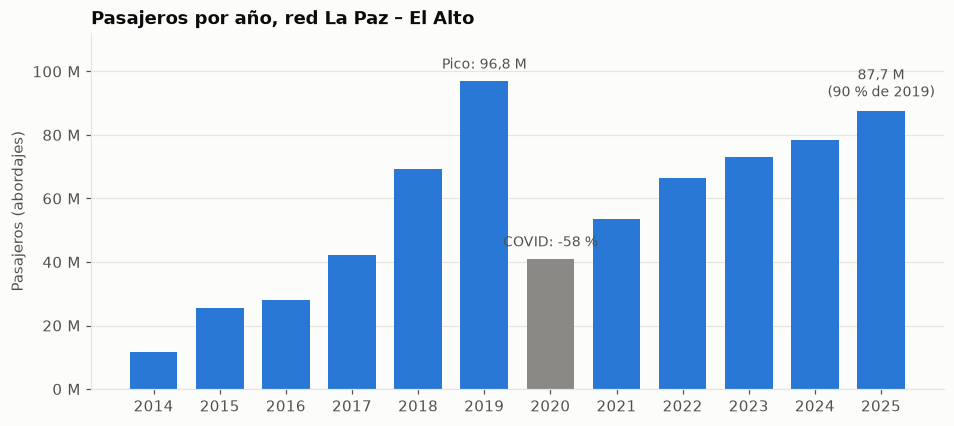

,pasajeros,var_pct,indice_2019,dias_operacion,promedio_diario
anio,,,,,
2014,11541743,NaN,11.9,216,"53,434.0"
2015,25388582,120.0,26.2,365,"69,557.8"
2016,27961821,10.1,28.9,366,"76,398.4"
2017,42067553,50.4,43.4,365,"115,253.6"
2018,69416181,65.0,71.7,365,"190,181.3"
2019,96842192,39.5,100.0,365,"265,321.1"
2020,40893145,-57.8,42.2,305,"134,075.9"
2021,53391664,30.6,55.1,365,"146,278.5"
2022,66357879,24.3,68.5,365,"181,802.4"


In [2]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colores = [viz.TINTA_3 if a == 2020 else viz.ACENTO for a in anual["anio"]]
ax.bar(anual["anio"], anual["pasajeros"], color=colores, width=0.72)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(viz.millones))
ax.set_xticks(anual["anio"])
ax.grid(axis="x", visible=False)
ax.set_title("Pasajeros por año, red La Paz – El Alto")
ax.set_ylabel("Pasajeros (abordajes)")

def nota(anio, texto, dy=3e6):
    y = anual.set_index("anio").loc[anio, "pasajeros"]
    ax.annotate(texto, (anio, y + dy), ha="center", va="bottom", fontsize=9, color=viz.TINTA_2)

nota(2019, f"Pico: {viz.num(kpi['pasajeros_2019']/1e6)} M")
nota(2020, f"COVID: {viz.num(kpi['caida_2020_pct'], 0)} %")
nota(2025, f"{viz.num(kpi['pasajeros_2025']/1e6)} M\n({viz.num(kpi['indice_2025_vs_2019'], 0)} % de 2019)")
ax.set_ylim(0, 112e6)
viz.guardar(fig, "01_anual")
plt.show()

anual[["anio", "pasajeros", "var_pct", "indice_2019", "dias_operacion", "promedio_diario"]].set_index("anio")

**Lectura:**
- La red creció por **expansión**: cada inauguración (Azul y Naranja en 2017; Blanca, Celeste, Morada
  y Café en 2018; Plateada en 2019) sumó un escalón. El pico fue 2019 con ~96,8 M de pasajeros.
- La cuarentena de 2020 recortó la demanda un 58 % (sin servicio en abril y mayo).
  La serie mensual también muestra la caída de noviembre de 2019 (conflicto post-electoral).
- 2025 cerró con **87,7 M (+11,9 % interanual)**, pero todavía **~9,5 % por debajo de 2019**.
  Recuperación sostenida, aún incompleta. ¿Es pareja entre líneas? Ver §3.

## 2. Serie mensual y estacionalidad

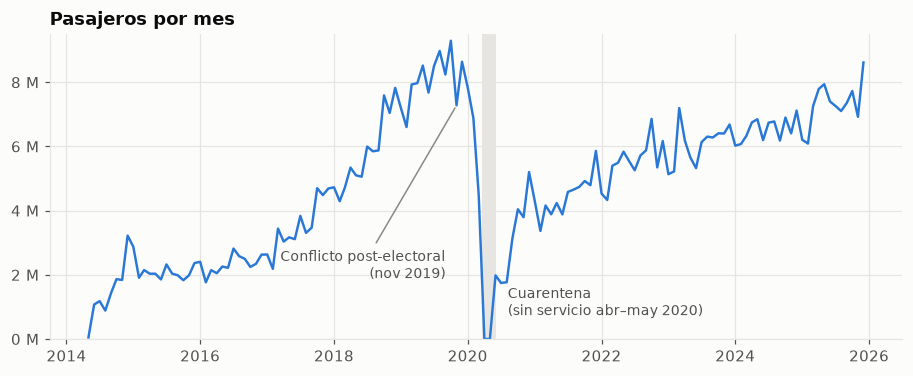

In [3]:
m = t["mensual"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(m["mes"], m["pasajeros"], color=viz.ACENTO, lw=1.6)
ax.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2020-06-01"), color=viz.GRILLA, lw=0)
ax.annotate("Cuarentena\n(sin servicio abr–may 2020)", (pd.Timestamp("2020-06-01"), 0.6e6),
            xytext=(8, 0), textcoords="offset points", fontsize=9, color=viz.TINTA_2, va="bottom")
ax.annotate("Conflicto post-electoral\n(nov 2019)", (pd.Timestamp("2019-11-01"), 7.28e6),
            xytext=(pd.Timestamp("2019-09-01"), 1.9e6), textcoords="data", ha="right", fontsize=9, color=viz.TINTA_2,
            arrowprops={"arrowstyle": "-", "color": viz.TINTA_3})
ax.yaxis.set_major_formatter(mticker.FuncFormatter(viz.millones))
ax.set_ylim(0, 9.5e6)
ax.set_title("Pasajeros por mes")
viz.guardar(fig, "01_mensual")
plt.show()

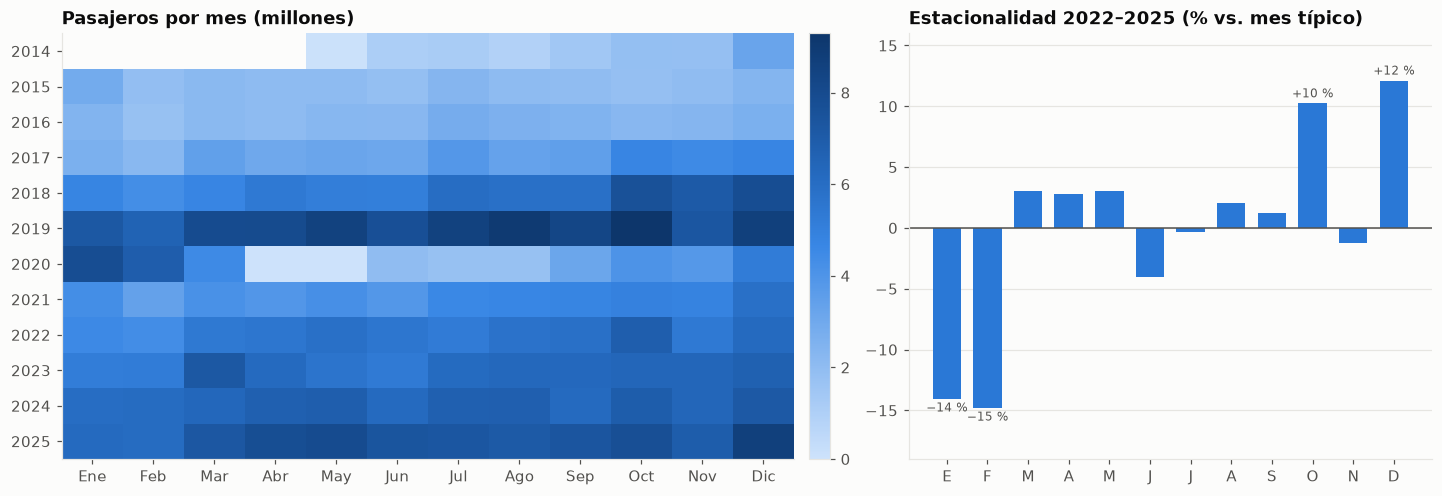

In [4]:
mat = d.matriz_mensual(t["mensual"])
ind = d.indice_estacional(t["mensual"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]},
                             layout="constrained")
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", viz.SECUENCIAL)
im = a1.imshow(mat.to_numpy() / 1e6, aspect="auto", cmap=cmap)
a1.set_xticks(range(12), d.MESES)
a1.set_yticks(range(len(mat)), mat.index)
a1.grid(False)
a1.set_title("Pasajeros por mes (millones)")
fig.colorbar(im, ax=a1, fraction=0.04, pad=0.02)

# Variación porcentual frente a un mes típico (0 = mes típico).
var = (ind - 1) * 100
a2.bar(range(12), var, color=viz.ACENTO, width=0.7)
a2.axhline(0, color=viz.TINTA_2, lw=1)
a2.set_xticks(range(12), [m[0] for m in d.MESES])
a2.set_ylim(-19, 16)
a2.set_title(f"Estacionalidad {d.ANIOS_ESTACIONALIDAD[0]}–{d.ANIOS_ESTACIONALIDAD[-1]} (% vs. mes típico)")
a2.grid(axis="x", visible=False)
for x, v in enumerate(var):
    if abs(v) >= 8:
        a2.annotate(f"{v:+.0f} %".replace("-", "−"), (x, v), ha="center", va="bottom" if v > 0 else "top",
                    fontsize=8, color=viz.TINTA_2, xytext=(0, 2 if v > 0 else -2), textcoords="offset points")
viz.guardar(fig, "01_estacionalidad")
plt.show()

**Lectura:** fuera del período COVID la estacionalidad es moderada y estable:
- **Enero y febrero** son los meses más bajos (14-15 % por debajo de un mes típico): vacaciones escolares y
  universitarias de verano y Carnaval.
- **Octubre y diciembre** son los picos (+10 % y +12 %): ciclo académico y comercio de fin de año.
- Implicación: la demanda es **estructural** (trabajo y estudio), no turística. Una línea nueva debe
  pensarse para viajes cotidianos, no para picos estacionales.

## 3. Líneas: quién mueve a quién y cuánto rinde cada km de cable

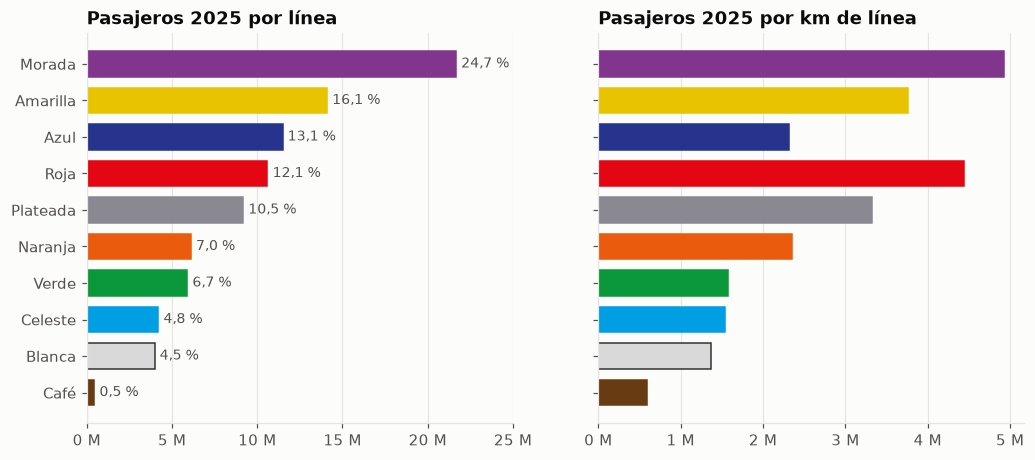

,pasajeros,participacion_pct,km,km_pct,estaciones,pasajeros_por_km,var_vs_anio_previo_pct,var_vs_2019_pct
linea,,,,,,,,
Morada,"21,663,328.0",24.7,4.4,14.2,3,"4,929,197.0",2.5,2.8
Amarilla,"14,099,826.0",16.1,3.8,12.1,4,"3,758,951.2",14.1,-13.8
Azul,"11,486,761.0",13.1,5.0,16.0,5,"2,313,640.2",10.8,16.7
Roja,"10,602,920.0",12.1,2.4,7.7,3,"4,442,874.5",11.3,-12.9
Plateada,"9,178,149.0",10.5,2.8,8.9,3,"3,321,204.6",12.5,47.4
Naranja,"6,110,889.0",7.0,2.6,8.4,4,"2,351,698.7",17.8,-30.9
Verde,"5,901,375.0",6.7,3.7,12.0,4,"1,582,138.1",25.6,-28.5
Celeste,"4,202,324.0",4.8,2.7,8.8,4,"1,536,386.4",31.6,-35.6
Blanca,"3,978,489.0",4.5,2.9,9.3,4,"1,374,547.1",18.7,-40.1


In [5]:
lin = d.resumen_lineas(t)
orden = lin.sort_values("pasajeros").index

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
viz.barras_lineas(a1, orden, lin.loc[orden, "pasajeros"], height=0.7)
a1.xaxis.set_major_formatter(mticker.FuncFormatter(viz.millones))
a1.set_title("Pasajeros 2025 por línea")
for y, l in enumerate(orden):
    a1.text(lin.loc[l, "pasajeros"] + 3e5, y, f"{viz.num(lin.loc[l, 'participacion_pct'])} %",
            va="center", fontsize=9, color=viz.TINTA_2)
a1.set_xlim(0, 25e6)

viz.barras_lineas(a2, orden, lin.loc[orden, "pasajeros_por_km"], height=0.7)
a2.xaxis.set_major_formatter(mticker.FuncFormatter(viz.millones))
a2.set_title("Pasajeros 2025 por km de línea")
for ax in (a1, a2):
    ax.grid(axis="y", visible=False)
viz.guardar(fig, "01_lineas")
plt.show()

lin[["pasajeros", "participacion_pct", "km", "km_pct", "estaciones", "pasajeros_por_km",
     "var_vs_anio_previo_pct", "var_vs_2019_pct"]]

**Lectura:**
- **Morada** (6 de Marzo – Faro Murillo – San José/Obelisco, la conexión más directa de El Alto al centro
  de La Paz) lleva **1 de cada 4 pasajeros** (24,7 %) con el 14 % de los km. Es la más productiva:
  ~4,9 M pasajeros por km.
- **Roja** (16 de Julio – Estación Central) es la segunda más productiva por km. Las dos líneas que bajan
  de El Alto al centro son las más intensas.
- **Café** (0,7 km, 2 estaciones) apenas mueve 0,45 M/año: una línea de enlace muy corta y
  subutilizada.

### Recuperación post-COVID por línea (2019 = 100)

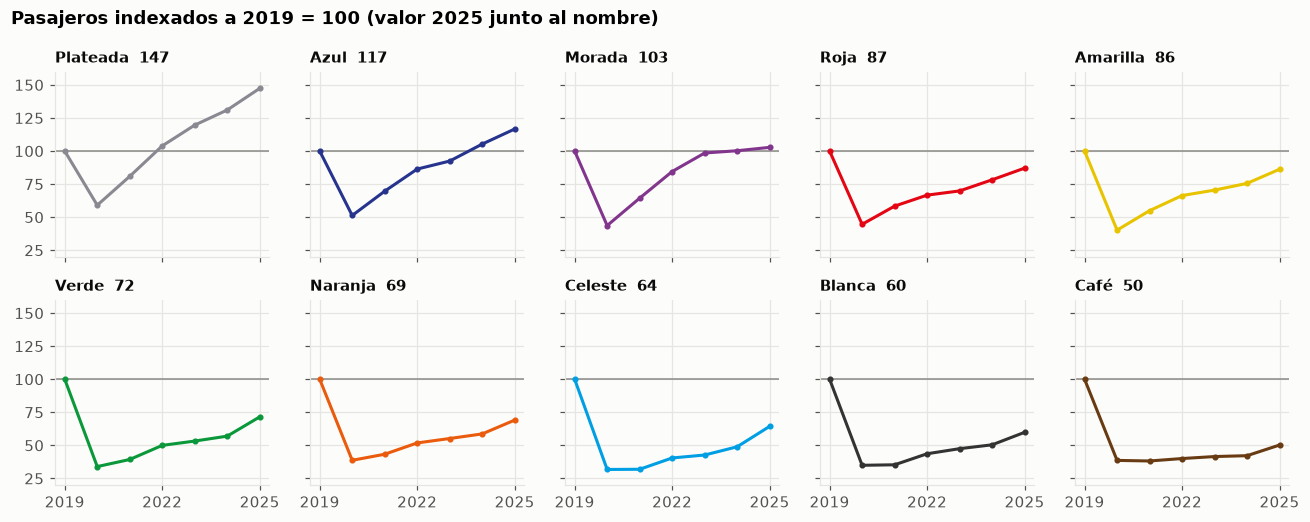

In [6]:
idx = d.indice_por_linea(t["por_linea"]).loc[2019:]
orden_idx = idx.loc[2025].sort_values(ascending=False).index
fig, axs = plt.subplots(2, 5, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, l in zip(axs.flat, orden_idx):
    ax.axhline(100, color=viz.TINTA_3, lw=1)
    ax.plot(idx.index, idx[l], color=viz.TRAZO_LINEA[l], lw=2, marker="o", ms=3)
    v = idx.loc[2025, l]
    ax.set_title(f"{l}  {v:.0f}", fontsize=10, loc="left")
    ax.set_xticks([2019, 2022, 2025])
    ax.set_ylim(20, 160)
fig.suptitle("Pasajeros indexados a 2019 = 100 (valor 2025 junto al nombre)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
viz.guardar(fig, "01_recuperacion")
plt.show()

**Lectura: la recuperación no es pareja, y el patrón es geográfico.**
- **Ya superaron 2019** las líneas que sirven a **El Alto**: Plateada (147: recorre el borde de El Alto
  entre 16 de Julio, Faro Murillo y Mirador), Azul (117: el eje de la Av. 16 de Julio en El Alto,
  Río Seco – 16 de Julio) y Morada (103).
- **Siguen muy por debajo** las líneas **internas de La Paz**: Café (50), Blanca (60), Celeste (64),
  Naranja (69) y Verde (72).
- Hipótesis para las fases siguientes: la demanda del teleférico la mueve sobre todo **El Alto**
  (población más grande, viajes largos y con desnivel hacia La Paz). En La Paz, la oferta competidora
  (minibuses, PumaKatari, auto propio) y los cambios de movilidad post-COVID pesan más.

## 4. Estaciones: alta concentración en pocos nodos

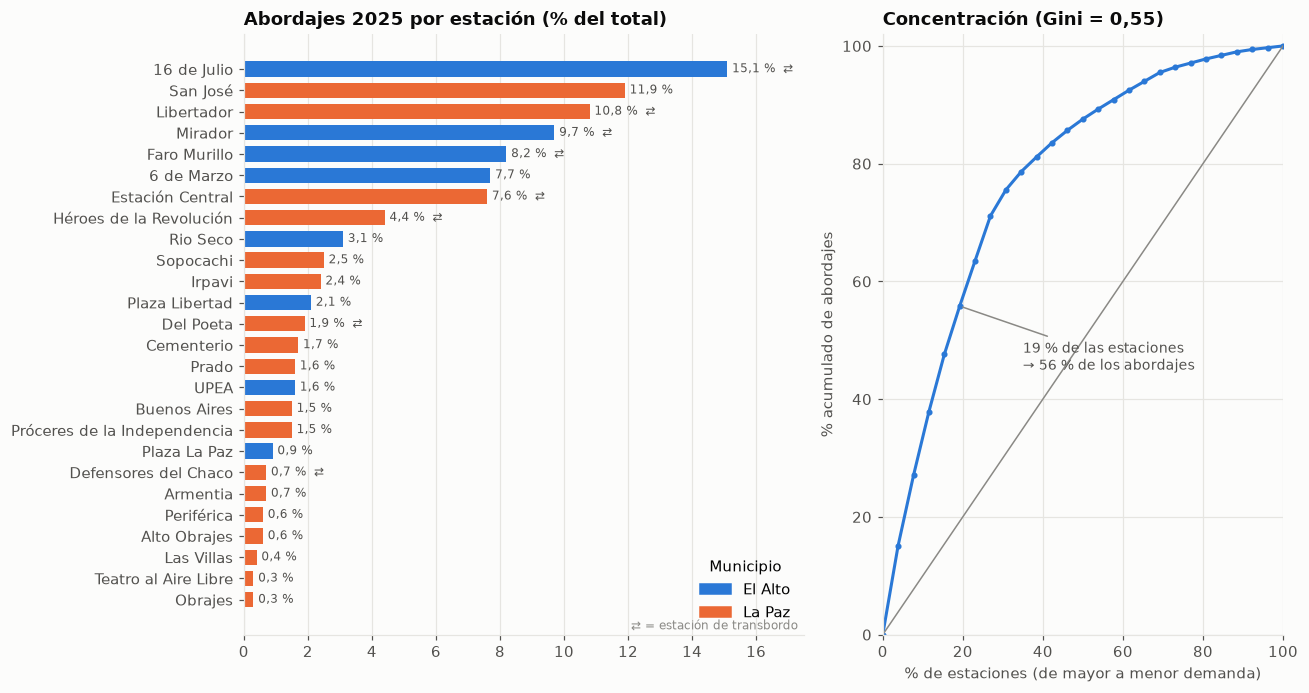

In [7]:
est = d.estaciones_fisicas(t)
col_mun = {"El Alto": viz.ACENTO, "La Paz": "#eb6834"}
e = est.sort_values("pct")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6.4), gridspec_kw={"width_ratios": [1.4, 1]})
a1.barh(e["nombre"], e["pct"], color=[col_mun[m] for m in e["municipio"]], height=0.72)
for y, (p, tr) in enumerate(zip(e["pct"], e["transbordo"])):
    a1.text(p + 0.15, y, f"{viz.num(p)} %" + ("  ⇄" if tr else ""), va="center", fontsize=8, color=viz.TINTA_2)
a1.set_title("Abordajes 2025 por estación (% del total)")
a1.grid(axis="y", visible=False)
a1.set_xlim(0, 17.5)
a1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in col_mun.values()],
          labels=list(col_mun), loc="lower right", title="Municipio")
a1.text(17.3, -1.4, "⇄ = estación de transbordo", ha="right", fontsize=8, color=viz.TINTA_3)

conc = d.curva_concentracion(est["pasajeros_est"])
a2.plot(np.r_[0, conc["pct_estaciones"]], np.r_[0, conc["pct_demanda"]], color=viz.ACENTO, marker="o", ms=3)
a2.plot([0, 100], [0, 100], color=viz.TINTA_3, lw=1)
x50, y50 = conc.loc[conc["pct_demanda"] >= 50].iloc[0]
a2.annotate(f"{x50:.0f} % de las estaciones\n→ {y50:.0f} % de los abordajes", (x50, y50),
            xytext=(35, 45), textcoords="data", fontsize=9, color=viz.TINTA_2,
            arrowprops={"arrowstyle": "-", "color": viz.TINTA_3})
a2.set_xlabel("% de estaciones (de mayor a menor demanda)")
a2.set_ylabel("% acumulado de abordajes")
a2.set_title(f"Concentración (Gini = {viz.num(kpi['gini_estaciones_2025'], 2)})")
a2.set_xlim(0, 100); a2.set_ylim(0, 102)
fig.tight_layout()
viz.guardar(fig, "01_estaciones")
plt.show()

### El Alto frente a La Paz: población, estaciones y abordajes

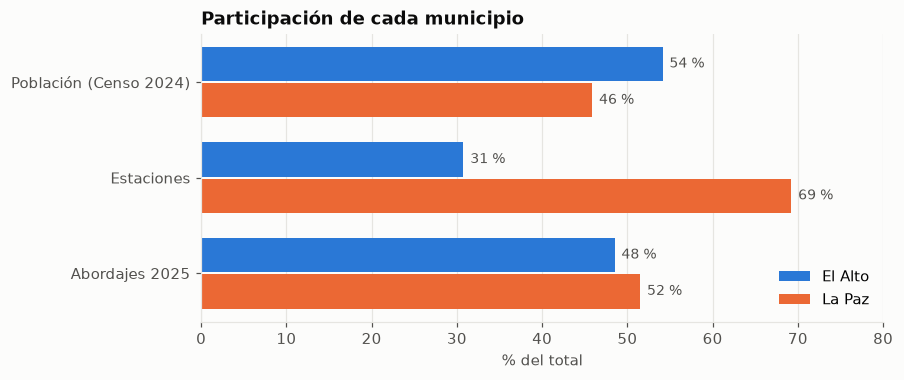

municipio,El Alto,La Paz
Población (Censo 2024),54.1,45.9
Estaciones,30.8,69.2
Abordajes 2025,48.5,51.5


In [8]:
mz = pd.read_parquet(PROCESSED / "censo" / "manzanos.parquet", columns=["municipio", "personas"])
pob = mz.groupby("municipio")["personas"].sum()
comp = pd.DataFrame({
    "Población (Censo 2024)": pob / pob.sum() * 100,
    "Estaciones": est.groupby("municipio").size() / len(est) * 100,
    "Abordajes 2025": est.groupby("municipio")["pct"].sum() / est["pct"].sum() * 100,
}).T

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(comp))
ax.barh(y - 0.19, comp["El Alto"], height=0.36, color=col_mun["El Alto"], label="El Alto")
ax.barh(y + 0.19, comp["La Paz"], height=0.36, color=col_mun["La Paz"], label="La Paz")
for yy, (a, b) in enumerate(zip(comp["El Alto"], comp["La Paz"])):
    ax.text(a + 0.8, yy - 0.19, f"{a:.0f} %", va="center", fontsize=9, color=viz.TINTA_2)
    ax.text(b + 0.8, yy + 0.19, f"{b:.0f} %", va="center", fontsize=9, color=viz.TINTA_2)
ax.set_yticks(y, comp.index)
ax.invert_yaxis()
ax.set_xlim(0, 80)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_xlabel("% del total")
ax.set_title("Participación de cada municipio")
viz.guardar(fig, "01_municipios")
plt.show()
comp.round(1)

**Lectura:**
- La demanda está **muy concentrada**: 5 estaciones (19 % del total) generan más de la mitad de los
  abordajes, y las 6 menos usadas no llegan al 3 %. Los nodos fuertes son **cabeceras en el borde de El
  Alto** (16 de Julio, Faro Murillo, 6 de Marzo, Mirador) y sus pares de llegada en La Paz (San José,
  Libertador, Estación Central).
- **El Alto tiene el 54 % de la población pero solo el 31 % de las estaciones (8 de 26)**, y aun así
  genera el 48 % de los abordajes. Cada estación alteña rinde mucho más que una paceña, señal de **demanda
  insatisfecha y de áreas de captación muy grandes** en El Alto.
- Las estaciones alteñas están casi todas sobre el **borde del altiplano** (la "ceja") y el eje de la
  Av. 16 de Julio. Todavía no se sabe cuánta población del interior y la periferia de El Alto queda a
  más de 15 minutos a pie de una estación: eso lo mide la Fase 3.

## 5. Conclusiones e hipótesis para las siguientes fases

| # | Hallazgo | Implicación para el proyecto |
|---|---|---|
| 1 | 87,7 M de pasajeros en 2025 (+11,9 %), aún 9,5 % bajo el pico de 2019 | El sistema sigue creciendo: hay espacio para una expansión |
| 2 | Las líneas que sirven a El Alto ya superaron 2019 (Plateada 147, Azul 117, Morada 103); las internas de La Paz siguen en 50-72 | La demanda la mueve El Alto → **buscar la nueva línea ahí primero** |
| 3 | El Alto: 54 % de la población, 31 % de las estaciones, 48 % de los abordajes | Alta productividad por estación = **subcobertura probable** (H2 del plan) |
| 4 | 5 estaciones concentran el 56 % de los abordajes (Gini 0,55) | Grandes áreas de captación → medir el acceso real a pie con pendiente (Fase 3) |
| 5 | Estacionalidad baja y estable (ene-feb −14 %, oct/dic +10-12 %) | Demanda cotidiana: diseñar para viajes de trabajo y estudio |
| 6 | Morada: 25 % de los pasajeros con 14 % de los km; Café: 0,5 % | La productividad por km depende de conectar zonas densas con el centro, no de la longitud |

**Siguiente paso (notebook 02-03):** cobertura poblacional a 5/10/15/20 minutos a pie, con la
velocidad corregida por pendiente, para cuantificar cuánta población queda lejos del cable y dónde.

## Anexo: exportación de datos para el sitio

In [9]:
from teleferico.export_web import exportar_demanda
exportar_demanda(t)
pd.Series(kpi)

pct_abordajes_el_alto_2025                                                        48.4
estaciones_el_alto                                                                   8
pasajeros_2025                                                                87672207
pasajeros_2024                                                                78340151
var_2025_vs_2024_pct                                                              11.9
pasajeros_2019                                                                96842192
indice_2025_vs_2019                                                               90.5
caida_2020_pct                                                                   -57.8
acumulado_2014_2025                                                          672798073
promedio_diario_2025                                                            240198
km_red                                                                            31.0
linea_top                                  